<a href="https://colab.research.google.com/github/sethkipsangmutuba/Recommender-System/blob/main/Recommender_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recommender Systems

## Objective
In this chapter, we will learn how to build a **movie recommendation system**. We will cover the following concepts and techniques:

1. **Creating a training pipeline** that can be trained with custom parameters.
2. **Nearest Neighbors** classifier and its implementation.
3. **Collaborative filtering** and how to apply it to build a recommender system.

By the end of this chapter, you will learn the following:

- How to create a **training pipeline**.
- How to **extract nearest neighbors**.
- How to build a **K-Nearest Neighbors (KNN)** classifier.
- How to **compute similarity scores** between items or users.
- How to **find similar users** using collaborative filtering.
- How to use these techniques to build a **movie recommendation system**.

## Creating a Training Pipeline

### What is a Training Pipeline?
- **Machine-learning systems** are generally composed of different modules that are combined in a **specific order** to achieve the desired outcome.
- The **scikit-learn library** provides tools to easily create these pipelines by concatenating various modules and functions together.

### How Pipelines Work:
- You specify the modules (such as **feature selection**, **data preprocessing**, or **classification algorithms**) and their corresponding parameters.
- Scikit-learn takes care of building the pipeline and processing the data in the correct sequence to train the system.

### Example Pipeline Structure:
- The pipeline can include various modules such as:
  - **Feature Selection**: Choosing important features from the dataset.
  - **Preprocessing**: Scaling or transforming data before training.
  - **Classification**: Implementing algorithms like **Extremely Random Forest** or **K-Nearest Neighbors**.

In this section, we will see how to build a pipeline that selects the top K features from the input data and classifies them using an **Extremely Random Forest** classifier.

## Nearest Neighbors Classifier

- The **Nearest Neighbors** algorithm is fundamental for many recommendation systems.
- It works by finding the closest data points to a given query point based on a **distance metric** (like **Euclidean distance**).
  
In the context of a movie recommender system:
- We can find **similar movies** based on features such as genre, director, actors, or user ratings.

## Collaborative Filtering

- **Collaborative Filtering** is a popular technique for building recommendation systems.
- It works by analyzing user behavior and identifying **similar users** or **items**.
- There are two main types:
  - **User-based collaborative filtering**: Recommending items based on similar users' preferences.
  - **Item-based collaborative filtering**: Recommending items that are similar to items a user has liked before.

## Building a Movie Recommendation System

By combining the techniques discussed:
1. We will use a **training pipeline** to process the data.
2. We will apply a **K-Nearest Neighbors (KNN)** classifier to find **similar movies** or **users**.
3. Using **collaborative filtering**, we will **compute similarity scores** to recommend movies based on user preferences.

## Conclusion

Building recommender systems involves multiple stages, including:
- Creating a pipeline to process and train the data.
- Using **nearest neighbor** algorithms to find similar items.
- Applying **collaborative filtering** to provide personalized recommendations.

This chapter provides the foundation for understanding how these methods can be used to create an effective **movie recommendation system**.


In [ ]:
from sklearn.datasets import make_classification
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier

# Step 1: Generate some labeled sample data for training and testing
X, y = make_classification(n_samples=150,
                            n_features=25,
                            n_classes=3,
                            n_informative=6,
                            n_redundant=0,
                            random_state=7)

# Step 2: Define the first block of the pipeline - feature selector
k_best_selector = SelectKBest(f_regression, k=9)

# Step 3: Define the second block of the pipeline - Extremely Random Forest classifier
classifier = ExtraTreesClassifier(n_estimators=60, max_depth=4)

# Step 4: Construct the pipeline by joining the feature selector and classifier
processor_pipeline = Pipeline([
    ('selector', k_best_selector),
    ('erf', classifier)
])

# Step 5: Set parameters for the individual blocks of the pipeline
processor_pipeline.set_params(selector__k=7, erf__n_estimators=30)

# Step 6: Train the pipeline with the generated data
processor_pipeline.fit(X, y)

# Step 7: Predict outputs for the input data
output = processor_pipeline.predict(X)
print("\nPredicted output:\n", output)

# Step 8: Print the score of the classifier using the labeled training data
print("\nScore:", processor_pipeline.score(X, y))

# Step 9: Extract the features chosen by the selector block
status = processor_pipeline.named_steps['selector'].get_support()
selected = [i for i, x in enumerate(status) if x]

print("\nIndices of selected features:", ', '.join([str(x) for x in selected]))



Predicted output:
 [0 2 2 0 2 0 2 1 0 1 1 2 0 0 2 2 1 0 0 0 0 2 1 1 2 2 0 0 1 2 1 2 1 0 2 2 1
 1 2 2 2 0 1 0 2 1 2 2 1 0 1 2 2 2 2 0 2 2 0 2 2 0 1 0 2 1 1 1 1 2 1 0 0 2
 0 0 1 2 2 0 0 1 2 2 0 0 0 0 2 2 2 1 2 0 2 1 2 2 0 0 1 1 1 1 2 2 0 2 0 1 1
 0 2 1 0 0 1 1 1 1 0 0 0 1 2 0 0 0 2 1 2 0 0 1 0 1 1 0 1 1 1 1 2 2 0 1 2 0
 2 2]

Score: 0.8866666666666667

Indices of selected features: 4, 7, 8, 12, 14, 17, 22


##Extracting the nearest neighbors
Recommender systems employ the concept of nearest neighbors to find good
recommendations. Nearest neighbors refers to the process of finding the closest points to
the input point from the given dataset. This is frequently used to build classification
systems that classify a datapoint based on the proximity of the input data point to various
classes


K Nearest Neighbors:
1 ==> [5.1 2.2]
2 ==> [3.8 3.7]
3 ==> [3.4 1.9]
4 ==> [2.9 2.5]
5 ==> [5.7 3.5]


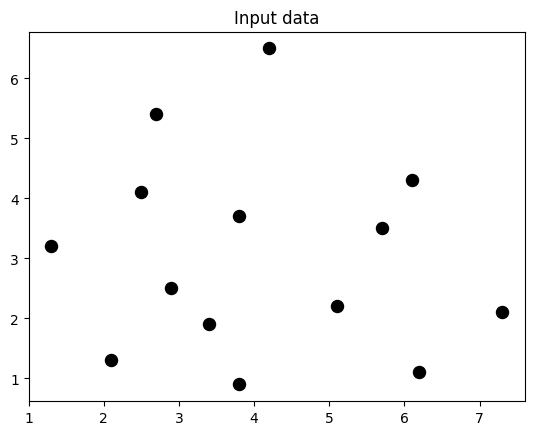

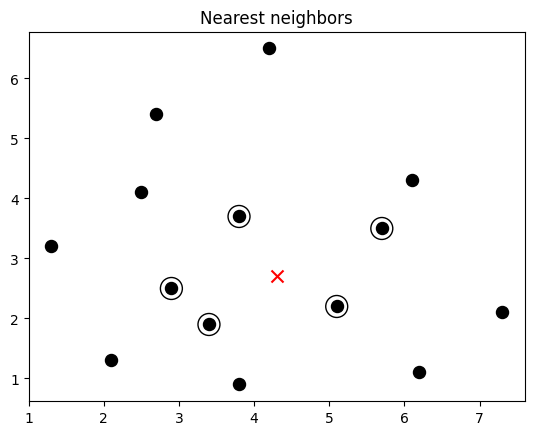

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Step 1: Define sample 2D datapoints
X = np.array([[2.1, 1.3], [1.3, 3.2], [2.9, 2.5], [2.7, 5.4], [3.8, 0.9],
              [7.3, 2.1], [4.2, 6.5], [3.8, 3.7], [2.5, 4.1], [3.4, 1.9],
              [5.7, 3.5], [6.1, 4.3], [5.1, 2.2], [6.2, 1.1]])

# Step 2: Define the number of nearest neighbors you want to extract
k = 5  # We want the 5 nearest neighbors

# Step 3: Define a test datapoint that will be used to extract the K nearest neighbors
test_datapoint = [4.3, 2.7]

# Step 4: Plot the input data using circular shaped black markers
plt.figure()
plt.title('Input data')
plt.scatter(X[:, 0], X[:, 1], marker='o', s=75, color='black')

# Step 5: Create and train a K Nearest Neighbors model using the input data
knn_model = NearestNeighbors(n_neighbors=k, algorithm='ball_tree').fit(X)

# Step 6: Extract the nearest neighbors to the test datapoint
distances, indices = knn_model.kneighbors([test_datapoint])

# Step 7: Print the 'k' nearest neighbors
print("\nK Nearest Neighbors:")
for rank, index in enumerate(indices[0][:k], start=1):
    print(f"{rank} ==> {X[index]}")

# Step 8: Visualize the nearest neighbors along with the test datapoint
plt.figure()
plt.title('Nearest neighbors')
plt.scatter(X[:, 0], X[:, 1], marker='o', s=75, color='k')

# Highlight the nearest neighbors
plt.scatter(X[indices[0], 0], X[indices[0], 1], marker='o', s=250, color='k', facecolors='none')

# Highlight the test datapoint
plt.scatter(test_datapoint[0], test_datapoint[1], marker='x', s=75, color='r')

# Show the plot
plt.show()


# K-Nearest Neighbors (KNN) Classifier

## Objective
The **K-Nearest Neighbors (KNN)** classifier is a **classification algorithm** that assigns a class to a data point based on the **majority class** of its nearest neighbors. In this section, we will:

- Build a **KNN classifier** to classify data points.
- Visualize the **decision boundaries** of the classifier.
- Identify the **nearest neighbors** to a test data point.

## How KNN Works

1. **Training Step**:
   - The KNN algorithm does not explicitly learn a model. Instead, it memorizes the training dataset.
   
2. **Prediction Step**:
   - When a new data point is encountered, the algorithm finds the **K nearest neighbors** (data points) in the training set based on a **distance metric** (e.g., Euclidean distance).
   - It then assigns the class label that is most common among the K nearest neighbors.

3. **Distance Metric**:
   - The most common metric is **Euclidean distance**, but other metrics such as **Manhattan distance** or **Cosine similarity** can also be used.

## Visualizing Decision Boundaries

- KNN creates decision boundaries that partition the feature space based on the class labels of neighboring points.
- The **decision boundaries** can be visualized by plotting the data points and showing where the classifier switches from one class to another.

## Nearest Neighbors to a Test Point

- One of the key features of KNN is that we can identify and analyze the **nearest neighbors** of any test point.
- This allows us to understand the **local structure** of the data and how the classification is made.

## Conclusion
- The **KNN classifier** is simple but effective for classification tasks.
- By understanding the **nearest neighbors** and visualizing decision boundaries, we can gain insights into how the algorithm makes predictions and identify potential areas for improvement.


Predicted output: 1


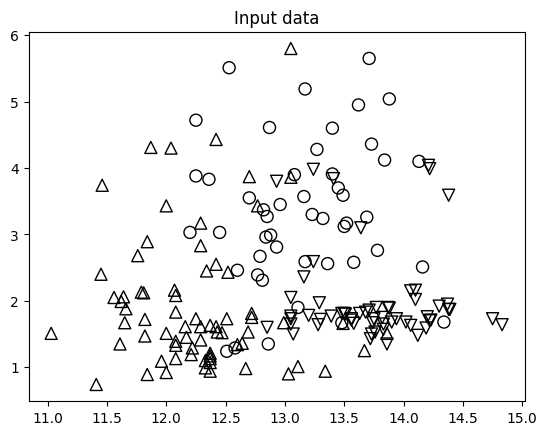

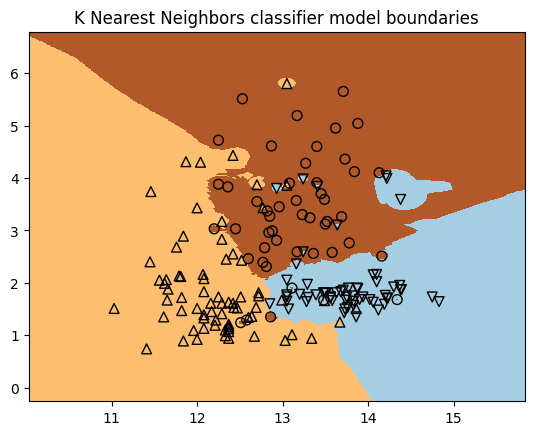

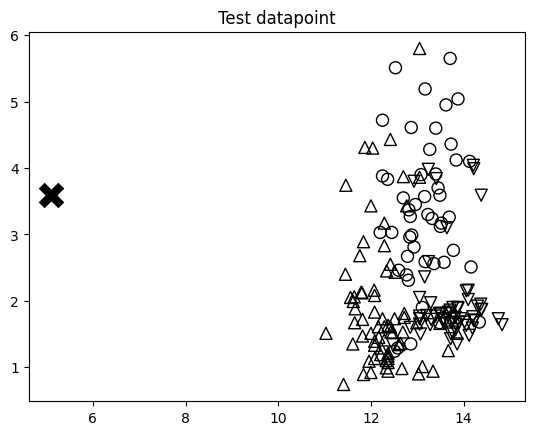

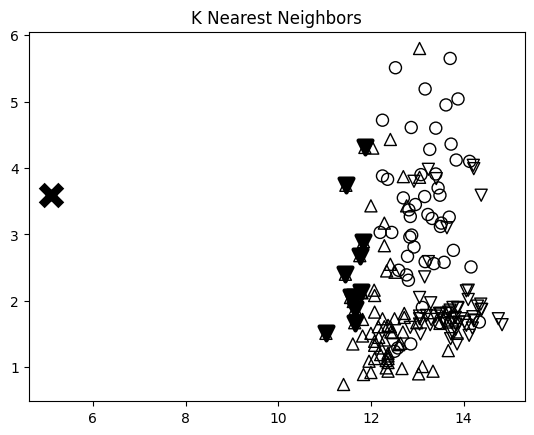

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn import neighbors
from sklearn.datasets import load_wine

# Step 1: Load Wine dataset
wine = load_wine()
X, y = wine.data[:, :2], wine.target  # Use only the first two features for 2D visualization

# Step 2: Visualize the input data using different marker shapes based on classes
plt.figure()
plt.title('Input data')
marker_shapes = 'v^os'  # Assign a different marker for each class
mapper = [marker_shapes[i] for i in y]
for i in range(X.shape[0]):
    plt.scatter(X[i, 0], X[i, 1], marker=mapper[i], s=75, edgecolors='black', facecolors='none')

# Step 3: Define the number of nearest neighbors
num_neighbors = 12

# Step 4: Define the step size of the grid for visualizing classifier boundaries
step_size = 0.01

# Step 5: Create the K Nearest Neighbors classifier model
classifier = neighbors.KNeighborsClassifier(num_neighbors, weights='distance')

# Step 6: Train the model using the training data
classifier.fit(X, y)

# Step 7: Create the mesh grid of values to visualize decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
x_values, y_values = np.meshgrid(np.arange(x_min, x_max, step_size),
                                 np.arange(y_min, y_max, step_size))

# Step 8: Evaluate the classifier on all points in the grid to visualize the boundaries
output = classifier.predict(np.c_[x_values.ravel(), y_values.ravel()])

# Step 9: Visualize the predicted output (classifier boundaries)
output = output.reshape(x_values.shape)
plt.figure()
plt.pcolormesh(x_values, y_values, output, cmap=cm.Paired)

# Step 10: Overlay the training data on top of this color mesh
for i in range(X.shape[0]):
    plt.scatter(X[i, 0], X[i, 1], marker=mapper[i], s=50, edgecolors='black', facecolors='none')

# Step 11: Set the X and Y limits and display the title
plt.xlim(x_values.min(), x_values.max())
plt.ylim(y_values.min(), y_values.max())
plt.title('K Nearest Neighbors classifier model boundaries')

# Step 12: Define a test data point and visualize its position
test_datapoint = [5.1, 3.6]
plt.figure()
plt.title('Test datapoint')

# Overlay the training points
for i in range(X.shape[0]):
    plt.scatter(X[i, 0], X[i, 1], marker=mapper[i], s=75, edgecolors='black', facecolors='none')

# Overlay the test datapoint
plt.scatter(test_datapoint[0], test_datapoint[1], marker='x', linewidth=6, s=200, facecolors='black')

# Step 13: Extract the K nearest neighbors to the test data point
_, indices = classifier.kneighbors([test_datapoint])
indices = indices.astype(int)[0]

# Step 14: Plot the K nearest neighbors
plt.figure()
plt.title('K Nearest Neighbors')
for i in indices:
    plt.scatter(X[i, 0], X[i, 1], marker=mapper[y[i]], linewidth=3, s=100, facecolors='black')

# Step 15: Overlay the test data point
plt.scatter(test_datapoint[0], test_datapoint[1], marker='x', linewidth=6, s=200, facecolors='black')

# Step 16: Overlay the input data points
for i in range(X.shape[0]):
    plt.scatter(X[i, 0], X[i, 1], marker=mapper[i], s=75, edgecolors='black', facecolors='none')

# Step 17: Print the predicted output for the test data point
print("Predicted output:", classifier.predict([test_datapoint])[0])

# Step 18: Show all plots
plt.show()


#Computing similarity score

In [ ]:
import json
import numpy as np

# Function to simulate argument parsing for notebook/colab
def get_input_args(user1, user2, score_type):
    return {
        'user1': user1,
        'user2': user2,
        'score_type': score_type
    }

# Compute the Euclidean distance score between user1 and user2
def euclidean_score(dataset, user1, user2):
    if user1 not in dataset:
        raise TypeError('Cannot find ' + user1 + ' in the dataset')
    if user2 not in dataset:
        raise TypeError('Cannot find ' + user2 + ' in the dataset')

    # Movies rated by both user1 and user2
    common_movies = {}

    # Extract the movies rated by both users
    for item in dataset[user1]:
        if item in dataset[user2]:
            common_movies[item] = 1

    # If there are no common movies, then the score is 0
    if len(common_movies) == 0:
        return 0

    # Compute the squared differences between the ratings
    squared_diff = []
    for item in dataset[user1]:
        if item in dataset[user2]:
            squared_diff.append(np.square(dataset[user1][item] - dataset[user2][item]))

    # Return the Euclidean score (inversely proportional to distance)
    return 1 / (1 + np.sqrt(np.sum(squared_diff)))


# Compute the Pearson correlation score between user1 and user2
def pearson_score(dataset, user1, user2):
    if user1 not in dataset:
        raise TypeError('Cannot find ' + user1 + ' in the dataset')
    if user2 not in dataset:
        raise TypeError('Cannot find ' + user2 + ' in the dataset')

    # Movies rated by both user1 and user2
    common_movies = {}

    # Extract the movies rated by both users
    for item in dataset[user1]:
        if item in dataset[user2]:
            common_movies[item] = 1

    num_ratings = len(common_movies)

    # If there are no common movies, then the score is 0
    if num_ratings == 0:
        return 0

    # Calculate the sum of ratings of all the common movies
    user1_sum = np.sum([dataset[user1][item] for item in common_movies])
    user2_sum = np.sum([dataset[user2][item] for item in common_movies])

    # Calculate the sum of squares of ratings of all the common movies
    user1_squared_sum = np.sum([np.square(dataset[user1][item]) for item in common_movies])
    user2_squared_sum = np.sum([np.square(dataset[user2][item]) for item in common_movies])

    # Calculate the sum of products of the ratings of the common movies
    sum_of_products = np.sum([dataset[user1][item] * dataset[user2][item] for item in common_movies])

    # Calculate the Pearson correlation score
    Sxy = sum_of_products - (user1_sum * user2_sum / num_ratings)
    Sxx = user1_squared_sum - np.square(user1_sum) / num_ratings
    Syy = user2_squared_sum - np.square(user2_sum) / num_ratings

    # If there is no deviation, then the score is 0
    if Sxx * Syy == 0:
        return 0

    # Return the Pearson score
    return Sxy / np.sqrt(Sxx * Syy)


# Simulate user input (you can change these values for testing)
user1 = 'User1'
user2 = 'User2'
score_type = 'Euclidean'  # Change this to 'Pearson' for Pearson similarity

# Example dataset (replace this with your actual ratings data)
ratings_data = {
    "User1": {"Movie1": 5, "Movie2": 3, "Movie3": 4},
    "User2": {"Movie1": 4, "Movie2": 4, "Movie3": 5},
    "User3": {"Movie1": 2, "Movie2": 5, "Movie3": 3}
}

# Get the input arguments
args = get_input_args(user1, user2, score_type)

# Compute the similarity score based on the input arguments
if args['score_type'] == 'Euclidean':
    print("\nEuclidean score:")
    print(euclidean_score(ratings_data, args['user1'], args['user2']))
else:
    print("\nPearson score:")
    print(pearson_score(ratings_data, args['user1'], args['user2']))



Euclidean score:
0.36602540378443865


#Finding similar users using collaborative filtering

In [6]:
import json
import numpy as np

# Define Pearson similarity function
def pearson_score(dataset, user1, user2):
    if user1 not in dataset:
        raise TypeError('Cannot find ' + user1 + ' in the dataset')
    if user2 not in dataset:
        raise TypeError('Cannot find ' + user2 + ' in the dataset')

    common_movies = {item for item in dataset[user1] if item in dataset[user2]}
    num_ratings = len(common_movies)

    if num_ratings == 0:
        return 0

    user1_ratings = np.array([dataset[user1][item] for item in common_movies])
    user2_ratings = np.array([dataset[user2][item] for item in common_movies])

    user1_mean = np.mean(user1_ratings)
    user2_mean = np.mean(user2_ratings)

    numerator = np.sum((user1_ratings - user1_mean) * (user2_ratings - user2_mean))
    denominator = np.sqrt(np.sum((user1_ratings - user1_mean) ** 2) * np.sum((user2_ratings - user2_mean) ** 2))

    if denominator == 0:
        return 0

    return numerator / denominator

# Function to find similar users
def find_similar_users(dataset, user, num_users):
    if user not in dataset:
        raise TypeError('Cannot find ' + user + ' in the dataset')

    scores = np.array([[x, pearson_score(dataset, user, x)] for x in dataset if x != user])
    scores_sorted = np.argsort(scores[:, 1].astype(float))[::-1]
    top_users = scores_sorted[:num_users]
    return scores[top_users]

# Example dataset
ratings_data = {
    "User1": {"Movie1": 5, "Movie2": 3, "Movie3": 4},
    "User2": {"Movie1": 4, "Movie2": 4, "Movie3": 5},
    "User3": {"Movie1": 2, "Movie2": 5, "Movie3": 3},
    "User4": {"Movie1": 5, "Movie2": 2, "Movie3": 1}
}

# Input user
user = 'User1'

# Find top 3 similar users
print('\nUsers similar to', user + ':\n')
similar_users = find_similar_users(ratings_data, user, 3)
print('User\t\t\tSimilarity score')
print('-' * 41)
for item in similar_users:
    print(f'{item[0]}\t\t{round(float(item[1]), 2)}')



Users similar to User1:

User			Similarity score
-----------------------------------------
User4		0.72
User2		0.0
User3		-0.98
